In [1]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import cmcrameri.cm as cmc


In [2]:

def parse_comsol_data(filepath):
    """
    Parse COMSOL data file and return organized DataFrame.
    
    Parameters:
    -----------
    filepath : str
        Path to the COMSOL data file
        
    Returns:
    --------
    pd.DataFrame
        DataFrame with columns for coordinates, physical parameters, U_in, and Sb_option
    """
    
    with open(filepath, 'r') as file:
        lines = file.readlines()
    
    # Find the header line with column names
    header_line = None
    data_start = None
    
    for i, line in enumerate(lines):
        if line.startswith('% r;z;'):
            header_line = line.strip()
            data_start = i + 1
            break
    
    if header_line is None:
        raise ValueError("Could not find header line starting with '% r;z;'")
    
    # Parse the header to extract column information
    header_line = header_line[2:]  # Remove '% ' prefix
    
    # Split the header and extract parameter names and conditions
    columns = header_line.split(';')
    
    # Parse column names to extract parameter names, U_in values, and Sb_option values
    parsed_columns = []
    
    for col in columns:
        if '@' in col:
            # Extract parameter name and conditions
            parts = col.split('@')
            param_name = parts[0].strip()
            conditions = parts[1].strip()
            
            # Extract U_in value
            u_in_match = re.search(r'U_in=([0-9E.-]+)', conditions)
            u_in = float(u_in_match.group(1)) if u_in_match else None
            
            # Extract Sb_option value
            sb_match = re.search(r'Sb_option=([0-9]+)', conditions)
            sb_option = int(sb_match.group(1)) if sb_match else None
            
            parsed_columns.append({
                'original_name': col,
                'param_name': param_name,
                'u_in': u_in,
                'sb_option': sb_option
            })
        else:
            # Coordinate columns (r, z)
            parsed_columns.append({
                'original_name': col,
                'param_name': col,
                'u_in': None,
                'sb_option': None
            })
    
    # Read the data
    data_lines = lines[data_start:]
    
    # Parse data rows
    data_rows = []
    for line in data_lines:
        if line.strip():  # Skip empty lines
            values = [float(x) for x in line.strip().split(';')]
            data_rows.append(values)
    
    # Create DataFrame with original column structure
    df_raw = pd.DataFrame(data_rows, columns=[col['original_name'] for col in parsed_columns])
    
    # Reorganize data by grouping parameters by U_in and Sb_option
    organized_data = []
    
    # Get coordinate columns (r, z)
    coord_cols = [col for col in parsed_columns if col['u_in'] is None]
    
    # Get unique combinations of U_in and Sb_option
    param_cols = [col for col in parsed_columns if col['u_in'] is not None]
    unique_conditions = set((col['u_in'], col['sb_option']) for col in param_cols)
    
    for u_in, sb_option in unique_conditions:
        # Get all parameter columns for this condition
        condition_cols = [col for col in param_cols 
                         if col['u_in'] == u_in and col['sb_option'] == sb_option]
        
        # For each row in the original data
        for idx, row in df_raw.iterrows():
            # Start with coordinates
            row_data = {'r': row[coord_cols[0]['original_name']], 
                       'z': row[coord_cols[1]['original_name']]}
            
            # Add condition identifiers
            row_data['U_in'] = u_in
            row_data['Sb_option'] = sb_option
            
            # Add all parameters for this condition
            for col in condition_cols:
                param_name = col['param_name']
                # Clean up parameter names (remove units and extra info)
                clean_param_name = param_name.split('(')[0].strip()
                row_data[clean_param_name] = row[col['original_name']]
            
            organized_data.append(row_data)
    
    # Create the final organized DataFrame
    df_organized = pd.DataFrame(organized_data)
    
    # Sort by U_in, Sb_option, and spatial coordinates
    df_organized = df_organized.sort_values(['U_in', 'Sb_option', 'r', 'z']).reset_index(drop=True)
    
    return df_organized
def calculate_excess_pressure(df):
    """
    Calculate excess pressure as linproj_r - rho_e*g*depth.
    
    Parameters:
    -----------
    df : pd.DataFrame
        The organized dataframe from parse_comsol_data
        
    Returns:
    --------
    pd.DataFrame
        DataFrame with added P_excess column
    """
    df_copy = df.copy()
    
    # Constants
    rho_e = 2700  # kg/m³
    g = 9.81      # m/s²
    
    # Calculate excess pressure
    # P_excess = linproj_r - rho_e * g * depth
    # Note: z is negative (z=0 at surface, z=-5000 at 5km depth)
    # So depth = -z (depth is positive)
    depth = -df_copy['z']  # Convert negative z to positive depth
    df_copy['P_excess'] = df_copy['linproj_r'] - (rho_e * g * depth +2.5e6+1e5)  # Adding 2.5 MPa offset for lithostatic pressure at surface
    
    print(f"Debug: z range: {df_copy['z'].min()} to {df_copy['z'].max()}")
    print(f"Debug: depth range: {depth.min()} to {depth.max()}")
    print(f"Debug: linproj_r range: {df_copy['linproj_r'].min()} to {df_copy['linproj_r'].max()}")
    print(f"Debug: P_excess range: {df_copy['P_excess'].min()} to {df_copy['P_excess'].max()}")
    
    return df_copy


In [3]:
def get_colormap(colormap):
    """
    Try to get a colormap from cmcrameri.cm, else fallback to matplotlib colormaps.
    """
    import matplotlib.pyplot as plt
    import cmcrameri.cm as cmc
    try:
        return getattr(cmc, colormap)
    except AttributeError:
        try:
            return plt.get_cmap(colormap)
        except Exception:
            print(f"Colormap '{colormap}' not found in cmcrameri or matplotlib. Using 'viridis'.")
            return plt.cm.viridis

In [4]:

# File path
filepath_sb_0 = '../../data/3_outgassing_models/conduit_wall_Sb0_colima.txt'

filepath_sb_4 = '../../data/3_outgassing_models/conduit_wall_Sb4_colima.txt'

filepath_sb_6 = '../../data/3_outgassing_models/conduit_wall_Sb6_colima.txt'



# Load and organize the data
print("Loading COMSOL conduit data...")
df_sb_0 = parse_comsol_data(filepath_sb_0)
df_sb_4 = parse_comsol_data(filepath_sb_4)
df_sb_6 = parse_comsol_data(filepath_sb_6)

# Combine dataframes
df = pd.concat([df_sb_0, df_sb_4, df_sb_6], ignore_index=True)

# Display basic information about the dataset
print(f"\nDataset loaded successfully!")
print(f"Shape: {df.shape}")
print(f"Columns: {list(df.columns)}")

# Show unique values for key grouping variables

# Display first few rows
print(f"\nFirst 5 rows:")
print(df.head())

# Display summary statistics
print(f"\nSummary statistics:")
print(df.describe())

# Group by U_in and Sb_option to show data organization
print(f"\nData organization by U_in and Sb_option:")
grouped = df.groupby(['U_in', 'Sb_option']).size()
print(grouped)

# Save to CSV for easy access
#output_file = '.conduit_data_organized.csv'
#df.to_csv(output_file, index=False)
#print(f"\nData saved to: {output_file}")


# Create the main grid plot with variables as columns and sb_options as rows
selected_vars = ['Xc_nocap', 'Xg', 'rho_b', 'mu_m']
#plot_variables_vs_depth_grid(df, variables=selected_vars, colormap='batlow')

# 

Loading COMSOL conduit data...

Dataset loaded successfully!
Shape: (804518, 20)
Columns: ['r', 'z', 'U_in', 'Sb_option', 'Xc_nocap', 'Xc', 'Sb', 'Xg', 'spf.mu*spf.sr', 'rho_b', 'rho_m', 'Xm', 'T', 'linproj_r', 'mu_m', 'nu_b_inf', 'nu_c', 'mu_mbc', 'u_av', 'Cw']

First 5 rows:
      r            z     U_in  Sb_option  Xc_nocap        Xc   Sb   Xg  \
0  15.0 -2895.466455  0.00001        0.0  0.404593  0.404593  0.0  0.0   
1  15.0 -2886.777268  0.00001        0.0  0.404996  0.404996  0.0  0.0   
2  15.0 -2879.160042  0.00001        0.0  0.405351  0.405351  0.0  0.0   
3  15.0 -2878.132411  0.00001        0.0  0.405399  0.405399  0.0  0.0   
4  15.0 -2876.585622  0.00001        0.0  0.405471  0.405471  0.0  0.0   

   spf.mu*spf.sr   rho_b   rho_m        Xm       T     linproj_r  \
0       0.414363  2700.0  2700.0  0.595407  1223.0  8.331213e+07   
1       0.415329  2700.0  2700.0  0.595004  1223.0  8.308198e+07   
2       0.416179  2700.0  2700.0  0.594649  1223.0  8.288022e+07   
3    

In [5]:
df

,r,z,U_in,Sb_option,Xc_nocap,Xc,Sb,Xg,spf.mu*spf.sr,rho_b,rho_m,Xm,T,linproj_r,mu_m,nu_b_inf,nu_c,mu_mbc,u_av,Cw
0,15.0,-2895.466455,0.00001,0.0,0.404593,0.404593,0.000000,0.0,4.143631e-01,2700.0,2700.0,0.595407,1223.0,8.331213e+07,3.296130e+04,1.00000,4.714759,1.554046e+05,0.00001,0.030000
1,15.0,-2886.777268,0.00001,0.0,0.404996,0.404996,0.000000,0.0,4.153289e-01,2700.0,2700.0,0.595004,1223.0,8.308198e+07,3.296130e+04,1.00000,4.725796,1.557684e+05,0.00001,0.030000
2,15.0,-2879.160042,0.00001,0.0,0.405351,0.405351,0.000000,0.0,4.161789e-01,2700.0,2700.0,0.594649,1223.0,8.288022e+07,3.296130e+04,1.00000,4.735525,1.560891e+05,0.00001,0.030000
3,15.0,-2878.132411,0.00001,0.0,0.405399,0.405399,0.000000,0.0,4.162944e-01,2700.0,2700.0,0.594601,1223.0,8.285300e+07,3.296130e+04,1.00000,4.736842,1.561324e+05,0.00001,0.030000
4,15.0,-2876.585622,0.00001,0.0,0.405471,0.405471,0.000000,0.0,4.164665e-01,2700.0,2700.0,0.594529,1223.0,8.281203e+07,3.296130e+04,1.00000,4.738825,1.561978e+05,0.00001,0.030000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
804513,15.0,-1.423100,1.00000,6.0,0.402730,0.402730,0.034112,0.3,5.613000e+06,1891.1,2700.0,0.597270,1223.0,2.733600e+06,1.277100e+07,0.55186,4.664500,3.287400e+07,1.37970,0.002520
804514,15.0,-1.067100,1.00000,6.0,0.402740,0.402740,0.038622,0.3,5.525300e+06,1891.2,2700.0,0.597260,1223.0,2.687500e+06,1.263800e+07,0.55186,4.664500,3.253300e+07,1.37770,0.002538
804515,15.0,-0.711280,1.00000,6.0,0.402740,0.402740,0.042320,0.3,5.460400e+06,1891.3,2700.0,0.597260,1223.0,2.655800e+06,1.248300e+07,0.55186,4.664500,3.213400e+07,1.37610,0.002560
804516,15.0,-0.355580,1.00000,6.0,0.402740,0.402740,0.045016,0.3,5.423100e+06,1891.4,2700.0,0.597260,1223.0,2.623200e+06,1.234100e+07,0.55186,4.664600,3.176900e+07,1.37500,0.002580



Creating conduit analysis plot...
           r       z  U_in  Sb_option  Xc_nocap   Xc   Sb   Xg  spf.mu*spf.sr  \
229879  15.0 -3000.0   0.1        0.0       0.4  0.4  0.0  0.0    4036.077068   
488675  15.0 -3000.0   0.1        4.0       0.4  0.4  1.0  0.0    4036.077066   
742632  15.0 -3000.0   0.1        6.0       0.4  0.4  1.0  0.0    4036.100000   

         rho_b   rho_m   Xm       T     linproj_r          mu_m  nu_b_inf  \
229879  2700.0  2700.0  0.6  1223.0  9.339391e+07  32961.295979       1.0   
488675  2700.0  2700.0  0.6  1223.0  8.834732e+07  32961.295979       1.0   
742632  2700.0  2700.0  0.6  1223.0  8.309700e+07  32961.000000       1.0   

            nu_c         mu_mbc  u_av    Cw  
229879  4.591837  151352.889699   0.1  0.03  
488675  4.591837  151352.889699   0.1  0.03  
742632  4.591800  151350.000000   0.1  0.03  
None
axes.labelsize: 8.0
axes.titlesize: 9.0
xtick.labelsize: 6.0
ytick.labelsize: 6.0
legend.fontsize: 7.0
figure.titlesize: 10.0
8.0
Debug: z ran

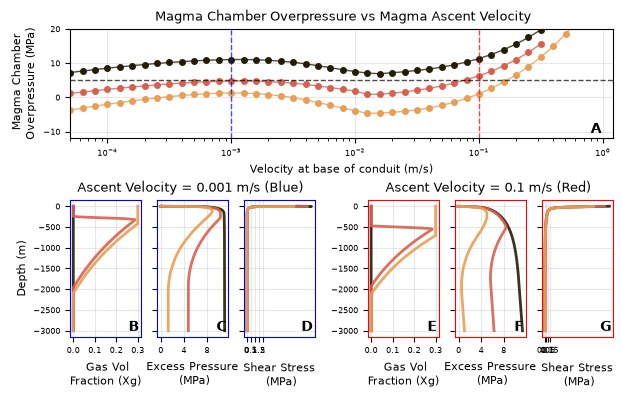

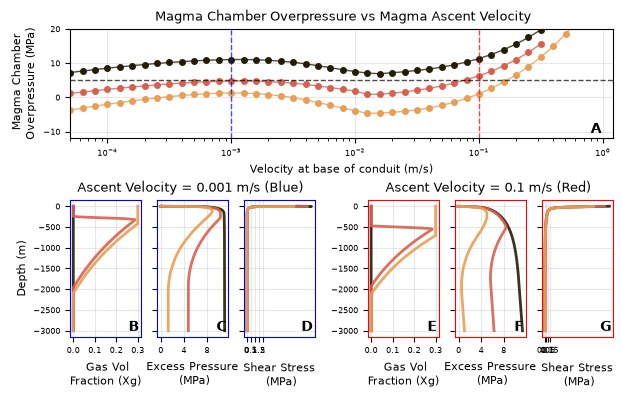

In [7]:
#Create the specific conduit analysis plot
print(f"\nCreating conduit analysis plot...")
#plot_conduit_analysis(df, colormap='gnuplot')

print(print(df[(df['U_in'] == 0.1) & (df['z'] == -3000)]))
#import pdb; pdb.set_trace()
plot_conduit_analysis_fig2(df, colormap='batlow', figsize=(7, 4), save_plot=True)




In [8]:

# ...existing code...

import matplotlib.patches as mpatches

def plot_conduit_analysis_fig2_presentation(df, colormap='batlow', figsize=(20, 14), save_plot=True):
    """
    Plot conduit analysis variables: Xc, rho_b, P_excess, Shear Stress, nu_magma, and Sb.
    Plus a Top row showing P_excess at deepest depth vs velocity.
    
    Parameters:
    -----------
    df : pd.DataFrame
        The organized dataframe from parse_comsol_data
    colormap : str
        Name of cmcrameri colormap to use (default: 'batlow')
    figsize : tuple
        Figure size for the entire plot
    save_plot : bool
        Whether to save plot to file
    """
        # Suppose main_axes is a 2D list: main_axes[row][col]
    from matplotlib.ticker import MaxNLocator, LogLocator
    import matplotlib as mpl
    mpl.rcParams.update({
        'font.family': 'sans-serif',
        'font.sans-serif': ['Helvetica', 'Arial', 'Liberation Sans', 'DejaVu Sans'],
        'font.size': 11,
        'axes.labelsize':11,
        'axes.titlesize': 11,
        'xtick.labelsize': 9.5,
        'ytick.labelsize': 9.5,
        'legend.fontsize': 11,
        'figure.titlesize': 11
    })
    # move xtick labels closer to the axis for top and bottom-row axes
  
    print("axes.labelsize:", mpl.rcParams['axes.labelsize'])      # Axis label font size
    print("axes.titlesize:", mpl.rcParams['axes.titlesize'])      # Axis title font size
    print("xtick.labelsize:", mpl.rcParams['xtick.labelsize'])    # X tick label font size
    print("ytick.labelsize:", mpl.rcParams['ytick.labelsize'])    # Y tick label font size
    print("legend.fontsize:", mpl.rcParams['legend.fontsize'])    # Legend font size
    print("figure.titlesize:", mpl.rcParams['figure.titlesize'])  # Figure suptitle font size
    
    print(mpl.rcParams['font.size'])  
    # Calculate P_excess
    df_analysis = calculate_excess_pressure(df)
    
    # Add (1-Sb) column for plotting
    if 'Sb' in df_analysis.columns:
        df_analysis['1-Sb'] = 1 - df_analysis['Sb']
    # Define variables to plot with their display names
    variables = {
        'Xg': r'$X_g$',
        'P_excess': r'$\Delta P$ (MPa)',
        'spf.mu*spf.sr': r'$\tau$ (MPa)',
    }
    

    #exctract_points_1e-3 = {0:1e-3,4:1e-3,6:1e-3}

    #extract_points_1e-1 = {0:1e-1,4:1e-1,6:1e-1}


    # Get unique sb_options and sort them
    sb_options = sorted(df_analysis['Sb_option'].unique())
    n_sb_options = len(sb_options)
    n_vars = len(variables)
    
    # Define colors for each Sb_option using 3 shades of blue from oslo colormap
    try:
        oslo_cmap = cmc.lajolla
    except AttributeError:
        oslo_cmap = plt.cm.Blues
    sb_colors = color_list = ['#0072B2', '#D55E00', '#009E73']
    sb_labels = {0: '100% Gas Loss', 4: 'Step at Xg = 0.3', 6: 'Sustained at Xg = 0.3'}
    sb_to_color = {sb_option: sb_colors[i % 3] for i, sb_option in enumerate(sb_options)}
    sb_to_label = {sb_option: sb_labels.get(sb_option, f'Sb = {sb_option}') for sb_option in sb_options}
    
    # Get unique velocities (use all data to get full range)
    velocities = sorted(df_analysis['U_in'].unique())
    n_velocities = len(velocities)
    
    # Create velocity to color mapping using log scale
    import numpy as np
    log_velocities = np.log10(velocities)
    log_min, log_max = log_velocities.min(), log_velocities.max()
    velocity_to_color = {vel: (np.log10(vel) - log_min) / (log_max - log_min) 
                        for vel in velocities}
    
    # Get the colormap (cmcrameri or matplotlib)
    cmap = get_colormap(colormap)
    
    # Create subplots: main grid + bottom row for P_excess vs U_in
    fig = plt.figure(figsize=figsize)
    
    # Create main grid (n_sb_options x n_vars)
    gs = fig.add_gridspec(2, n_vars*2+1, height_ratios=[0.65] + [1]*1,#n_sb_options, 
                          width_ratios=[1]*n_vars + [0.3] + [1]*n_vars, #[1, 1, 1, 0.3, 1, 1, 1],
                          hspace=1.4, wspace=0.25)
    
    # Create main subplot grid with shared x-axes in each column
    main_axes = []
    # Top row (span all columns)
    top_ax = fig.add_subplot(gs[0, :])

    # Bottom row: 3 left, 1 gap, 3 right
    bottom_axes = []
    for i in range(3):
        ax = fig.add_subplot(gs[1, i])
        bottom_axes.append(ax)
    # Skip gs[1, 3] (the gap)
    for i in range(4, 7):
        ax = fig.add_subplot(gs[1, i])
        bottom_axes.append(ax)
            
    main_axes.append(top_ax)
    main_axes.append(bottom_axes)
    # Plot main data

    selected_velocities = [0.001, 0.1]
    for i, sb_option in enumerate(sb_options):
        # Filter data for this sb_option
        df_filtered = df_analysis[df_analysis['Sb_option'] == sb_option].copy()
        for n, velocity in enumerate(selected_velocities):
            constant_row = n * n_vars
            for j, (var, var_name) in enumerate(variables.items()):
                ax = main_axes[1][constant_row + j]
                #import pdb;pdb.set_trace()
                # Special handling for 1-Sb - plot in same colors as bottom row
                if var == '1-Sb':
                    
                    data_subset = df_filtered[df_filtered['U_in'] == velocity]
                    if not data_subset.empty and '1-Sb' in data_subset.columns:
                        # Sort by depth for proper line plotting
                        data_subset = data_subset.sort_values('z')
                        depth = data_subset['z']
                        # Use the same color as in bottom row for this Sb_option
                        color = sb_to_color[sb_option]
                        ax.plot(data_subset['1-Sb'], depth, 
                                color=color, 
                                linewidth=2, alpha=0.9)
                else:
                    # Plot other variables with colormap
                    
                        data_subset = df_filtered[df_filtered['U_in'] == velocity]
                        
                        if not data_subset.empty and var in data_subset.columns:
                            # Sort by depth for proper line plotting
                            data_subset = data_subset.sort_values('z')
                            depth = data_subset['z']
                            
                            # Get color based on velocity using log scale
                            #color_index = velocity_to_color[velocity]  # Now already normalized 0-1
                            color = sb_to_color[sb_option]
                            if var in ['spf.mu*spf.sr', 'P_excess']:
                                plot_vals = data_subset[var] / 1e6
                                x_label = var_name.replace('(Pa)', '(MPa)')
                            elif var == 'Cw':
                                plot_vals = data_subset[var] * 100  # Convert to wt%
                                

                            else:
                                plot_vals = data_subset[var]
                                x_label = var_name
                            ax.plot(plot_vals, depth/1e3, color=color, linewidth=2, alpha=0.9)
                                        
                
                        # Set logarithmic scale for shear stress and magma viscosity only
                if var in [ 'mu_mbc','mu_m','nu_c']:
                    ax.set_xscale('log')
                if ax.get_xscale() == 'log':
                    pass
                else:
                    ax.xaxis.set_major_locator(MaxNLocator(nbins=4, prune=None))
                
                if var == 'Cw':
                    ax.set_xticks([0, 1, 2, 3])
                    ax.set_xticklabels(['0', '1', '2', '3'])
                elif var == 'spf.mu*spf.sr':
                    if n==1:
                        ticks = [0, 0.15]
                        ax.set_xticks(ticks)
                        ax.set_xticklabels([r'0',r'$0.15$']) 
                    else:
                        ticks = [0,2]
                        ax.set_xticks(ticks)
                        ax.set_xticklabels([r'0',2])
                elif var == 'Xg':
                
                    ticks = [0, 0.3]
                    ax.set_xticks(ticks)
                    ax.set_xticklabels([r'0',r'$0.3$']) 
                 
                
                elif var == 'nu_c':
                    ticks = [1, 1e2, 1e4]
                    ax.set_xticks(ticks)
                    ax.set_xticklabels([r'$1$', r'$10^{2}$', r'$10^{4}$'])
                # Reverse y-axis (depth increases downward)
                #ax.invert_yaxis()
                
                # Set labels and formatting
                # Always show x-axis labels and ticks, even for shared x-axes
                ax.set_xlabel(var_name)
                ax.tick_params(axis='x', labelbottom=True)
                if j == 0:  # Left column
                    ax.set_ylabel(f"Depth (km)",labelpad=12)#\n{sb_labels.get(sb_option, f'{sb_option}')}")
                else:
                    ax.set_ylabel("")
                    # Hide y-tick labels for non-leftmost plots
                    ax.set_yticklabels([])
                
                ax.grid(True, alpha=0.3)
                
            # Set title only for top row
            #if i == 0:
                #ax.set_title(var_name)
    
    # bbox0 = main_axes[1][0].get_position()
    # bbox2 = main_axes[1][2].get_position()
    # x0 = bbox0.x0
    # y0 = bbox0.y0
    # x1 = bbox2.x1
    # y1 = bbox0.y1


# raise/move axis titles (x labels on top, and y labels vertically centered)


    main_axes[1][4].set_title('Ascent Velocity = 0.1 m/s', y=-0.22,color='red')
    main_axes[1][1].set_title('Ascent Velocity = 0.001 m/s', y=-0.22,color='blue')
    for j, ax in enumerate(main_axes[1]):
        # Check if x-axis is log scale
         # Choose 3 ticks: min, geometric mean, max
        ax.xaxis.set_ticks_position('top')
        ax.xaxis.set_label_position('top')
        # for spine in ax.spines.values():
        #     spine.set_linewidth(2)
        # Remove top and right spines for a cleaner look
        ax.spines['bottom'].set_visible(False)
        ax.spines['right'].set_visible(False)
        # Add a shared y-label for the bottom row (centered vertically)
        # #fig.text(0.04, 0.5, "Depth (m)", va='center', rotation='vertical', fontsize=8)
        # for spine in ax.spines.values():
        #     if j>=3:
        #         spine.set_edgecolor('red')
        #     else:
        #         spine.set_edgecolor('blue')
        # Optionally, remove individual y-labels from all but the first subplot in the bottom row
        for j, ax in enumerate(main_axes[1]):
            if j != 0:
                ax.set_ylabel("")
    # Add colorbar for the main plots (excluding Sb)
    # Create a ScalarMappable for the colorbar with log normalization
    from matplotlib.colors import LogNorm
    sm = plt.cm.ScalarMappable(cmap=cmap, 
                              norm=LogNorm(vmin=min(velocities), 
                                          vmax=max(velocities)))
    sm.set_array([])
    

    sb_markers = ['o', 's', '^']  # Different markers for each Sb_option
    legend_handles = []
    for idx, sb_option in enumerate(sb_options):
        df_sb = df_analysis[df_analysis['Sb_option'] == sb_option].copy()
        p_excess_deepest = []
        velocities_plot = []
        colors_plot = []
        for velocity in velocities:
            df_vel = df_sb[df_sb['U_in'] == velocity]
            if not df_vel.empty:
                deepest_idx = df_vel['z'].idxmin()
                deepest_z = df_vel.loc[deepest_idx, 'z']
                deepest_p_excess = df_vel.loc[deepest_idx, 'P_excess']
                deepest_linproj = df_vel.loc[deepest_idx, 'linproj_r']
                p_excess_deepest.append(deepest_p_excess)
                # list to np array 
                
                velocities_plot.append(velocity)
                if len(velocities_plot) <= 3:
                    print(f"Sb_option {sb_option}, U_in {velocity}: z={deepest_z:.1f}, linproj_r={deepest_linproj:.2e}, P_excess={deepest_p_excess:.2e}")
                # Use the same normalization as sm (LogNorm)
                 # Get color based on velocity using log scale
                color_index = velocity_to_color[velocity]  # Now already normalized 0-1
                color = cmap(color_index)
                colors_plot.append(color)

        p_excess_deepest = np.array(p_excess_deepest)/1e6
        # Plot each point with its color
        top_ax.semilogx(velocities_plot, p_excess_deepest, color=sb_to_color[sb_option], alpha=0.95, linewidth=3)
        #for v, p, c in zip(velocities_plot, p_excess_deepest, colors_plot):
        #    print(c)
        #    top_ax.semilogx(v, p, marker='o', color=sb_to_color[sb_option], markersize=4, linewidth=0)       
        
        
        
        # top_ax.semilogx(velocities_plot, p_excess_deepest, 
        #         color=sb_to_color[sb_option],
        #         marker=sb_markers[idx % len(sb_markers)],
        #         markersize=8, linewidth=2, alpha=0.8,
        #         label=sb_to_label[sb_option])
        legend_handles.append(
            plt.Line2D([], [], color=sb_to_color[sb_option], linestyle='-',linewidth=3, label=sb_to_label[sb_option])
        )

    
    top_ax.set_ylabel(r'Inlet $\Delta P$(MPa)',labelpad=1)
    top_ax.set_title(' Outgassing models: Inlet Overpressure vs Magma Ascent Velocity')
    top_ax.grid(True, alpha=0.3)

    
    top_ax.set_xlabel('Inlet Velocity (m/s)', labelpad=1)  # Move xlabel closer
    top_ax.tick_params(axis='x', pad=1) 
    top_ax.tick_params(axis='y', pad=1) 
    # v line at 0.1 m/s and 0.001 m/s
    top_ax.axvline(0.1, color='red', linestyle='--', linewidth=1, alpha=0.7)
    top_ax.axvline(0.001, color='blue', linestyle='--', linewidth=1, alpha=0.7)
    # set hline at 0 Mpa and 5 MPa

    top_ax.set_ylim(-15, 15)
    
    top_ax.set_xlim([5e-5,1.2])
    # place a centered 3-column legend immediately below the top axis
    top_pos = top_ax.get_position()
    legend_y = top_pos.y0 - 0.075   # adjust -0.03 if you need more/less gap
    fig.legend(
        handles=legend_handles,
        title='Outgassing Model',
        ncol=3,
        fontsize=10,
        title_fontsize=11,
        loc='upper center',
        bbox_to_anchor=(0.5, legend_y),
        frameon=True
    )
    top_ax.spines['top'].set_visible(False)
    top_ax.spines['right'].set_visible(False)
    import string

    labels = list(string.ascii_uppercase)  # ['A', 'B', 'C', ...]
    label_idx = 0

    # Label the top_ax as 'A'
    top_ax.text(
        0.98, 0.02, labels[label_idx],
        transform=top_ax.transAxes,
        fontsize=10,
        fontweight='bold',
        va='bottom', ha='right'
    )
    for ax in main_axes[1]:
        # If x-label is on top, push it further up (axis coords: x=0..1, y relative to axis box)
        if ax.xaxis.get_label_position() == 'top':
            ax.xaxis.set_label_coords(0.5, 1.22)   # center horizontally, raise vertically (tweak 1.06..1.12)
  
        # Move y-label a bit outward and keep it vertically centered
        #ax.yaxis.set_label_coords(-0.12, 0.5)  
    for ax in [top_ax] + main_axes[1]:
        ax.tick_params(axis='x', which='both', pad=0)   # 0 = very close; use small positive or negative to tweak
        ax.xaxis.labelpad = 0                           # tighten xlabel distance
    # also tighten global default (optional)
    import matplotlib as mpl
    mpl.rcParams['xtick.major.pad'] = 0
    label_idx += 1
    # Then label the main grid subplots as B, C, ...
    for i, ax in enumerate(main_axes[1]):
        ax.text(
            0.98, 0.02, labels[label_idx],
            transform=ax.transAxes,
            fontsize=10,
            fontweight='bold',
            va='bottom', ha='right'
        )
        label_idx += 1
    fig.savefig(f'../../output_plots/3/figure2_conduit_analysis_Colima_Sb_comparison_flow_only_june26.pdf', dpi=300, bbox_inches='tight')
    fig.savefig(f'../../output_plots/3/figure2_conduit_analysis_Colima_Sb_comparison_flow_only_new_june26.svg', dpi=300, bbox_inches='tight')

    return fig



Creating conduit analysis plot...
           r       z  U_in  Sb_option  Xc_nocap   Xc   Sb   Xg  spf.mu*spf.sr  \
229879  15.0 -3000.0   0.1        0.0       0.4  0.4  0.0  0.0    4036.077068   
488675  15.0 -3000.0   0.1        4.0       0.4  0.4  1.0  0.0    4036.077066   
742632  15.0 -3000.0   0.1        6.0       0.4  0.4  1.0  0.0    4036.100000   

         rho_b   rho_m   Xm       T     linproj_r          mu_m  nu_b_inf  \
229879  2700.0  2700.0  0.6  1223.0  9.339391e+07  32961.295979       1.0   
488675  2700.0  2700.0  0.6  1223.0  8.834732e+07  32961.295979       1.0   
742632  2700.0  2700.0  0.6  1223.0  8.309700e+07  32961.000000       1.0   

            nu_c         mu_mbc  u_av    Cw  
229879  4.591837  151352.889699   0.1  0.03  
488675  4.591837  151352.889699   0.1  0.03  
742632  4.591800  151350.000000   0.1  0.03  
None
axes.labelsize: 11.0
axes.titlesize: 11.0
xtick.labelsize: 9.5
ytick.labelsize: 9.5
legend.fontsize: 11.0
figure.titlesize: 11.0
11.0
Debug: z

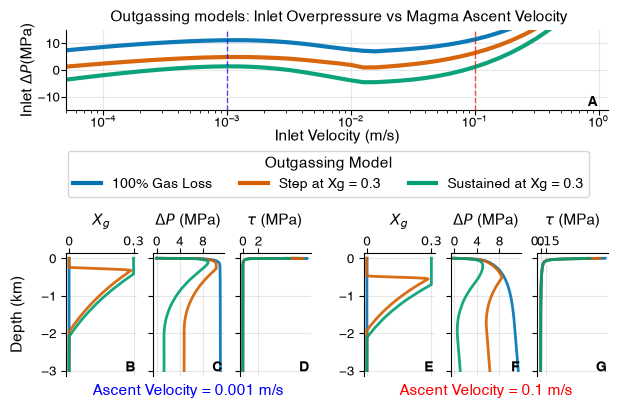

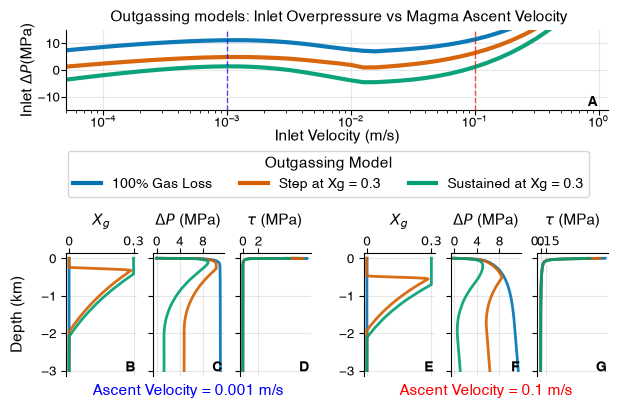

In [9]:
#Create the specific conduit analysis plot
print(f"\nCreating conduit analysis plot...")
#plot_conduit_analysis(df, colormap='gnuplot')

print(print(df[(df['U_in'] == 0.1) & (df['z'] == -3000)]))
#import pdb; pdb.set_trace()
plot_conduit_analysis_fig2_presentation(df, colormap='batlow', figsize=(7, 4.5), save_plot=True)




In [10]:

def parse_comsol_edge_data(filepath,var_names):
    with open(filepath, 'r') as file:
        lines = file.readlines()

    # Find the header line with column names
    header_line = None
    data_start = None

    for i, line in enumerate(lines):
        if line.startswith('% r;z;'):
            header_line = line.strip()
            data_start = i + 1
            break

    if header_line is None:
        raise ValueError("Could not find header line starting with '% r;z;'")

    # Parse the header to extract column information
    header_line = header_line[2:]  # Remove '% ' prefix

    #print(f"Header line: {header_line}")
    # Split the header and extract parameter names and conditions
    columns = header_line.split(';')

    # Parse column names to extract parameter names, U_in values, and Sb_option values
    parsed_columns = {}

    df = pd.DataFrame(index=range(len(columns)),columns=['param_name']+var_names)

    for i, col in enumerate(columns):
        #print('col:' + col)
        if '@' in col:
            # Extract parameter name and conditions
            parts = col.split('@')
            param_name = parts[0].strip()
            conditions = parts[1].strip()
            vars=conditions.split(',')

            
            
            df.at[i, 'param_name'] = param_name


            for k,var in enumerate(vars):
                if '=' in var:
                    key, value = var.split('=')
                    key = key.strip()
                    value = value.strip()
                    #print(f"Condition: {key} = {float(value)}")
                    df.at[i, var_names[k]] = float(value)
                else:
                    #print(f"Condition: {var_names[k]} : {var}")
                    df.at[i, var_names[k]] = var
        else:
            # Coordinate columns (r, z)
            df.at[i, 'param_name'] = col.strip()
            for k,var in enumerate(var_names):
                df.at[i, var_names[k]] = None
            
        
    data_lines = lines[data_start:]
    # # Parse data rows
    data_rows = []
    for line in data_lines:
        if line.strip():  # Skip empty lines
            values = [float(x) for x in line.strip().split(';')]
            data_rows.append(values)

    # # Create DataFrame with original column structure
    df_raw = pd.DataFrame(data_rows, columns=['r','z']+columns[2:])

    # Create new dataframe that will be the final export
    # params = df['param_name'].dropna().unique()
    #print(params.tolist()+var_names)

    # # Read the data

    params = df['param_name'].dropna().unique()

    params_list = params
    params_list = params_list[2:]
    print(params.tolist()+var_names)
    columns = params.tolist()+var_names

    # find unique values of each parameter
    df_vars = df.drop('param_name',axis=1)
    df_unique_vars= df_vars.drop_duplicates(keep='first').dropna(how='all')

    print('Number of rows in new dataframe')
    n_rows = df_raw.shape[0]*np.shape(df_unique_vars)[0]
    print(n_rows)

    output_df = pd.DataFrame(index=range(n_rows),columns=columns)
    print('Number of unique variables:' ,np.shape(df_unique_vars))


    param = params_list[0]
    for param in params_list:
        row_idx = 0
        for idx, row in df_unique_vars.iterrows():
            
            
                print('loop start')
                #print(f"Processing param: {param}")
                print(f"Processing param: {param}")
                row['param_name'] = param

                # find which rows in df match this row 
                mask = (df[row.index] == row.values).all(axis=1)
                matching_rows = df[mask]
                for raw_idx, raw_row in df_raw.iterrows():
                    value=raw_row.iloc[matching_rows.index.to_list()[0]]
                    
                    r = raw_row['r']
                    z = raw_row['z']

                    output_df.at[row_idx, 'r'] = r
                    output_df.at[row_idx, 'z'] = z
                    
                    for var_name in var_names:
                        print(row_idx,var_name)
                        output_df.at[row_idx, var_name] = row[var_name]  
                    output_df.at[row_idx, param] = value 
                    row_idx += 1

    new_names = []
    for i,name in enumerate(output_df.columns):
        
        new_names.append(name.split(' ')[0])

    output_df.columns = new_names

    return output_df






In [11]:
ge_fp_sb_0 = r'../../data/3_outgassing_models/ground_edge_Sb_0_colima.txt'


ge_fp_sb_4 = r'../../data/3_outgassing_models/ground_edge_Sb_4_colima.txt'

ge_fp_sb_6 = r'../../data/3_outgassing_models/ground_edge_Sb_6_colima.txt'



In [12]:

filepath = ge_fp_sb_0
var_names = ['U_in', 'param_def', 'tau_Xc', 'Sb_option', 'param_1']
df_ge_test0 = parse_comsol_edge_data(filepath,var_names)

filepath = ge_fp_sb_4
df_ge_test4 = parse_comsol_edge_data(filepath,var_names)
var_names = ['U_in', 'Sb_option', 'tau_Xc', 'param_1','param_def']
filepath = ge_fp_sb_6
df_ge_test6 = parse_comsol_edge_data(filepath,var_names)
df_ge_test = pd.concat([df_ge_test0, df_ge_test4, df_ge_test6], ignore_index=True)

df_ge = pd.concat([df_ge_test0, df_ge_test4, df_ge_test6], ignore_index=True)
#df_ge = pd.concat([df_ge_Sb0, df_ge_Sb4, df_ge_Sb6], ignore_index=True)

['r', 'z', 'u2 (m)', 'v2 (m)', 'w2 (m)', 'solid.RotrZ (rad)', 'U_in', 'param_def', 'tau_Xc', 'Sb_option', 'param_1']
Number of rows in new dataframe
12144
Number of unique variables: (138, 5)
loop start
Processing param: u2 (m)
0 U_in
0 param_def
0 tau_Xc
0 Sb_option
0 param_1
1 U_in
1 param_def
1 tau_Xc
1 Sb_option
1 param_1
2 U_in
2 param_def
2 tau_Xc
2 Sb_option
2 param_1
3 U_in
3 param_def
3 tau_Xc
3 Sb_option
3 param_1
4 U_in
4 param_def
4 tau_Xc
4 Sb_option
4 param_1
5 U_in
5 param_def
5 tau_Xc
5 Sb_option
5 param_1
6 U_in
6 param_def
6 tau_Xc
6 Sb_option
6 param_1
7 U_in
7 param_def
7 tau_Xc
7 Sb_option
7 param_1
8 U_in
8 param_def
8 tau_Xc
8 Sb_option
8 param_1
9 U_in
9 param_def
9 tau_Xc
9 Sb_option
9 param_1
10 U_in
10 param_def
10 tau_Xc
10 Sb_option
10 param_1
11 U_in
11 param_def
11 tau_Xc
11 Sb_option
11 param_1
12 U_in
12 param_def
12 tau_Xc
12 Sb_option
12 param_1
13 U_in
13 param_def
13 tau_Xc
13 Sb_option
13 param_1
14 U_in
14 param_def
14 tau_Xc
14 Sb_option
14 param

In [13]:
df_ge_test6

,r,z,u2,v2,w2,solid.RotrZ,U_in,Sb_option,tau_Xc,param_1,param_def
0,15.0,0.0,0.14129,0.0,0.31632,0.057408,1.0,6.0,0.0001,1.0,0.0
1,15.376,0.0,0.13809,0.0,0.29745,0.041615,1.0,6.0,0.0001,1.0,0.0
2,15.791,0.0,0.13404,0.0,0.28185,0.034307,1.0,6.0,0.0001,1.0,0.0
3,16.251,0.0,0.1297,0.0,0.2673,0.029642,1.0,6.0,0.0001,1.0,0.0
4,16.759,0.0,0.125,0.0,0.25325,0.026058,1.0,6.0,0.0001,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...
12388,2368.3,-876.36,-0.000651,0.0,-0.000067,-0.0,0.00001,6.0,0.0001,1.0,2.0
12389,2551.9,-952.87,-0.000619,0.0,-0.000037,-0.0,0.00001,6.0,0.0001,1.0,2.0
12390,2756.0,-1037.9,-0.000575,0.0,-0.000006,-0.0,0.00001,6.0,0.0001,1.0,2.0
12391,2992.0,-1136.2,-0.000515,0.0,0.000027,-0.0,0.00001,6.0,0.0001,1.0,2.0


In [14]:
df_ge

,r,z,u2,v2,w2,solid.RotrZ,U_in,param_def,tau_Xc,Sb_option,param_1
0,15.0,0.0,0.087587,0.0,0.19773,0.040601,0.31623,0.0,0.0001,0.0,1.0
1,15.183,0.0,0.086581,0.0,0.19116,0.03037,0.31623,0.0,0.0001,0.0,1.0
2,15.385,0.0,0.085289,0.0,0.18556,0.025625,0.31623,0.0,0.0001,0.0,1.0
3,15.608,0.0,0.083889,0.0,0.18021,0.022592,0.31623,0.0,0.0001,0.0,1.0
4,15.855,0.0,0.082372,0.0,0.17495,0.020317,0.31623,0.0,0.0001,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...
36676,2368.3,-876.36,-0.000651,0.0,-0.000067,-0.0,0.00001,2.0,0.0001,6.0,1.0
36677,2551.9,-952.87,-0.000619,0.0,-0.000037,-0.0,0.00001,2.0,0.0001,6.0,1.0
36678,2756.0,-1037.9,-0.000575,0.0,-0.000006,-0.0,0.00001,2.0,0.0001,6.0,1.0
36679,2992.0,-1136.2,-0.000515,0.0,0.000027,-0.0,0.00001,2.0,0.0001,6.0,1.0


In [15]:
df_ge['Sb_option'].unique()

array([0.0, 4.0, 6.0], dtype=object)

In [16]:


from matplotlib import gridspec


def plot_conduit_analysis_fig2_with_ground_deformation(df, df_ge, colormap='batlow', figsize=(20, 14), save_plot=True):
    """
    Plot conduit analysis variables: Xc, rho_b, P_excess, Shear Stress, nu_magma, and Sb.
    Plus a Top row showing P_excess at deepest depth vs velocity.
    
    Parameters:
    -----------
    df : pd.DataFrame
        The organized dataframe from parse_comsol_data
    colormap : str
        Name of cmcrameri colormap to use (default: 'batlow')
    figsize : tuple
        Figure size for the entire plot
    save_plot : bool
        Whether to save plot to file
    """
        # Suppose main_axes is a 2D list: main_axes[row][col]
    from matplotlib.ticker import MaxNLocator, LogLocator
    import matplotlib as mpl
    mpl.rcParams.update({
        'font.family': 'sans-serif',
        'font.sans-serif': ['Helvetica', 'Arial', 'Liberation Sans', 'DejaVu Sans'],
        'font.size': 11,
        'axes.labelsize':11,
        'axes.titlesize': 11,
        'xtick.labelsize': 9.5,
        'ytick.labelsize': 9.5,
        'legend.fontsize': 11,
        'figure.titlesize': 11
    })
    print("axes.labelsize:", mpl.rcParams['axes.labelsize'])      # Axis label font size
    print("axes.titlesize:", mpl.rcParams['axes.titlesize'])      # Axis title font size
    print("xtick.labelsize:", mpl.rcParams['xtick.labelsize'])    # X tick label font size
    print("ytick.labelsize:", mpl.rcParams['ytick.labelsize'])    # Y tick label font size
    print("legend.fontsize:", mpl.rcParams['legend.fontsize'])    # Legend font size
    print("figure.titlesize:", mpl.rcParams['figure.titlesize'])  # Figure suptitle font size
    
    print(mpl.rcParams['font.size'])  
    # Calculate P_excess
    df_analysis = calculate_excess_pressure(df)
    
    # Add (1-Sb) column for plotting
    if 'Sb' in df_analysis.columns:
        df_analysis['1-Sb'] = 1 - df_analysis['Sb']
    # Define variables to plot with their display names
    variables = {
        'Xg': ' Gas Vol\nFraction (Xg)',
        'P_excess': 'Excess Pressure\n (MPa)',
        'spf.mu*spf.sr': 'Shear Stress\n (MPa)',
    }
    

    #exctract_points_1e-3 = {0:1e-3,4:1e-3,6:1e-3}

    #extract_points_1e-1 = {0:1e-1,4:1e-1,6:1e-1}


    # Get unique sb_options and sort them
    sb_options = sorted(df_analysis['Sb_option'].unique())
    n_sb_options = len(sb_options)
    n_vars = len(variables)
    
    # Define colors for each Sb_option using 3 shades of blue from oslo colormap
    try:
        oslo_cmap = cmc.lajolla
    except AttributeError:
        oslo_cmap = plt.cm.Blues
    sb_colors = [oslo_cmap(0.05), oslo_cmap(0.5), oslo_cmap(0.7)]
    sb_labels = {0: '100% Gas Loss', 4: 'Step Gas Loss at Xg = 0.3', 6: 'Sustained Gas Loss at Xg = 0.3'}
    sb_to_color = {sb_option: sb_colors[i % 3] for i, sb_option in enumerate(sb_options)}
    sb_to_label = {sb_option: sb_labels.get(sb_option, f'Sb = {sb_option}') for sb_option in sb_options}
    
    # Get unique velocities (use all data to get full range)
    velocities = sorted(df_analysis['U_in'].unique())
    n_velocities = len(velocities)
    
    # Create velocity to color mapping using log scale
    import numpy as np
    log_velocities = np.log10(velocities)
    log_min, log_max = log_velocities.min(), log_velocities.max()
    velocity_to_color = {vel: (np.log10(vel) - log_min) / (log_max - log_min) 
                        for vel in velocities}
    
    # Get the colormap (cmcrameri or matplotlib)
    cmap = get_colormap(colormap)
    
    # Create subplots: main grid + bottom row for P_excess vs U_in
    fig = plt.figure(figsize=figsize)
    
    # Create main grid (n_sb_options x n_vars)
    gs = fig.add_gridspec(5, n_vars*2+1, height_ratios=[0.8] + [1]*1+[0.8]*3, #n_sb_options, 
                          width_ratios=[1]*n_vars + [0.3] + [1]*n_vars, #[1, 1, 1, 0.3, 1, 1, 1],
                          hspace=0.5, wspace=0.25)
    
    # Create main subplot grid with shared x-axes in each column
    main_axes = []
    # Top row (span all columns)
    top_ax = fig.add_subplot(gs[0, :])

    # Bottom row: 3 left, 1 gap, 3 right
    bottom_axes = []
    for i in range(3):
        ax = fig.add_subplot(gs[1, i])
        bottom_axes.append(ax)
    # Skip gs[1, 3] (the gap)
    for i in range(4, 7):
        ax = fig.add_subplot(gs[1, i])
        bottom_axes.append(ax)

    axes_last3 = []
    
    for i in range(3):
        sub_gs = gridspec.GridSpecFromSubplotSpec(
            1, 3, subplot_spec=gs[2+i, :], wspace=0.25
        )
        sub_ax = []
        for j in range(3):
            
            if i ==1:
                ax = fig.add_subplot(sub_gs[0, j], sharey=axes_last3[0][j])
            else:
                ax = fig.add_subplot(sub_gs[0, j])
            sub_ax.append(ax)
        axes_last3.append(sub_ax)
     
    main_axes.append(top_ax)
    main_axes.append(bottom_axes)
    main_axes.extend(axes_last3)
    
    # Plot main data

    selected_velocities = [0.1, 0.001]

    markers = ['-','--','-.']
    for i, sb_option in enumerate(sb_options):
        # Filter data for this sb_option
        df_filtered = df_analysis[df_analysis['Sb_option'] == sb_option].copy()
        for n, velocity in enumerate(selected_velocities):
            constant_row = n * n_vars
            for j, (var, var_name) in enumerate(variables.items()):
                ax = main_axes[1][constant_row + j]
                
                #import pdb;pdb.set_trace()
                # Special handling for 1-Sb - plot in same colors as bottom row
                if var == '1-Sb':
                    
                    data_subset = df_filtered[df_filtered['U_in'] == velocity]
                    if not data_subset.empty and '1-Sb' in data_subset.columns:
                        # Sort by depth for proper line plotting
                        data_subset = data_subset.sort_values('z')
                        depth = data_subset['z']
                        # Use the same color as in bottom row for this Sb_option
                        color = sb_to_color[sb_option]
                        ax.plot(data_subset['1-Sb'], depth, 
                                color=color, 
                                linewidth=1.5, linestyle=markers[j], alpha=0.9)
                else:
                    # Plot other variables with colormap
                    
                        data_subset = df_filtered[df_filtered['U_in'] == velocity]
                        
                        if not data_subset.empty and var in data_subset.columns:
                            # Sort by depth for proper line plotting
                            data_subset = data_subset.sort_values('z')
                            depth = data_subset['z']
                            
                            # Get color based on velocity using log scale
                            #color_index = velocity_to_color[velocity]  # Now already normalized 0-1
                            color = sb_to_color[sb_option]
                            if var in ['spf.mu*spf.sr', 'P_excess']:
                                plot_vals = data_subset[var] / 1e6
                                x_label = var_name.replace('(Pa)', '(MPa)')
                            elif var == 'Cw':
                                plot_vals = data_subset[var] * 100  # Convert to wt%
                                

                            else:
                                plot_vals = data_subset[var]
                                x_label = var_name
                            ax.plot(plot_vals, depth, color=color, linewidth=1.5, linestyle=markers[j], alpha=0.9)
                                        
                
                        # Set logarithmic scale for shear stress and magma viscosity only
                if var in [ 'mu_mbc','mu_m','nu_c']:
                    ax.set_xscale('log')
                if ax.get_xscale() == 'log':
                    pass
                else:
                    ax.xaxis.set_major_locator(MaxNLocator(nbins=4, prune=None))
                
                if var == 'Cw':
                    ax.set_xticks([0, 1, 2, 3])
                    ax.set_xticklabels(['0', '1', '2', '3'])
                elif var == 'spf.mu*spf.sr':
                    if n==1:
                        ticks = [0, 0.5, 1,1.5,2]
                        ax.set_xticks(ticks)
                        ax.set_xticklabels([r'0', r'$0.5$', r'$1$',1.5,2])
                    else:
                        ticks = [0,0.05, 0.1, 0.15]
                        ax.set_xticks(ticks)
                        ax.set_xticklabels([r'0', r'$0.05$', r'$0.1$', r'$0.15$'])    
                elif var == 'nu_c':
                    ticks = [1, 1e2, 1e4]
                    ax.set_xticks(ticks)
                    ax.set_xticklabels([r'$1$', r'$10^{2}$', r'$10^{4}$'])
                # Reverse y-axis (depth increases downward)
                #ax.invert_yaxis()
                
                # Set labels and formatting
                # Always show x-axis labels and ticks, even for shared x-axes
                ax.set_xlabel(var_name)
                ax.tick_params(axis='x', labelbottom=True)
                if j == 0:  # Left column
                    ax.set_ylabel(f"Depth (m)")#\n{sb_labels.get(sb_option, f'{sb_option}')}")
                else:
                    ax.set_ylabel("")
                    # Hide y-tick labels for non-leftmost plots
                    ax.set_yticklabels([])
                
                ax.grid(True, alpha=0.3)
                
            # Set title only for top row
            #if i == 0:
                #ax.set_title(var_name)
    

  



    bottom_row = 1

    main_axes[bottom_row][1].set_title('Ascent Velocity = 0.1 m/s (Blue) ')
    main_axes[bottom_row][4].set_title('Ascent Velocity = 0.001 m/s (Red) ')
    for j, ax in enumerate(main_axes[bottom_row]):
        # Check if x-axis is log scale
         # Choose 3 ticks: min, geometric mean, max
        
        # Add a shared y-label for the bottom row (centered vertically)
        #fig.text(0.04, 0.5, "Depth (m)", va='center', rotation='vertical', fontsize=8)
        for spine in ax.spines.values():
            if j>=3:
                spine.set_edgecolor('red')
            else:
                spine.set_edgecolor('blue')
        # Optionally, remove individual y-labels from all but the first subplot in the bottom row
        for j, ax in enumerate(main_axes[bottom_row]):
            if j != 0:
                ax.set_ylabel("")
    # Add colorbar for the main plots (excluding Sb)
    # Create a ScalarMappable for the colorbar with log normalization
    from matplotlib.colors import LogNorm
    sm = plt.cm.ScalarMappable(cmap=cmap, 
                              norm=LogNorm(vmin=min(velocities), 
                                          vmax=max(velocities)))
    sm.set_array([])
    
    # Plot P_excess at deepest depth vs U_in for each Sb_option
    sb_markers = ['o', 's', '^']  # Different markers for each Sb_option
    legend_handles = []
    for idx, sb_option in enumerate(sb_options):
        df_sb = df_analysis[df_analysis['Sb_option'] == sb_option].copy()
        p_excess_deepest = []
        velocities_plot = []
        colors_plot = []
        for velocity in velocities:
            df_vel = df_sb[df_sb['U_in'] == velocity]
            if not df_vel.empty:
                deepest_idx = df_vel['z'].idxmin()
                deepest_z = df_vel.loc[deepest_idx, 'z']
                deepest_p_excess = df_vel.loc[deepest_idx, 'P_excess']
                deepest_linproj = df_vel.loc[deepest_idx, 'linproj_r']
                p_excess_deepest.append(deepest_p_excess)
                # list to np array 
                
                velocities_plot.append(velocity)
                if len(velocities_plot) <= 3:
                    print(f"Sb_option {sb_option}, U_in {velocity}: z={deepest_z:.1f}, linproj_r={deepest_linproj:.2e}, P_excess={deepest_p_excess:.2e}")
                # Use the same normalization as sm (LogNorm)
                 # Get color based on velocity using log scale
                color_index = velocity_to_color[velocity]  # Now already normalized 0-1
                color = cmap(color_index)
                colors_plot.append(color)

        p_excess_deepest = np.array(p_excess_deepest)/1e6
        # Plot each point with its color
        top_ax.semilogx(velocities_plot, p_excess_deepest, color=sb_to_color[sb_option], alpha=0.8, linewidth=1)
        for v, p, c in zip(velocities_plot, p_excess_deepest, colors_plot):
            print(c)
            top_ax.semilogx(v, p, marker='o', color=sb_to_color[sb_option], markersize=4, linewidth=0)       
        
        
        
        # top_ax.semilogx(velocities_plot, p_excess_deepest, 
        #         color=sb_to_color[sb_option],
        #         marker=sb_markers[idx % len(sb_markers)],
        #         markersize=8, linewidth=2, alpha=0.8,
        #         label=sb_to_label[sb_option])
        legend_handles.append(
            plt.Line2D([], [], color=sb_to_color[sb_option], marker=sb_markers[idx % len(sb_markers)], linestyle='-', markersize=10, label=sb_to_label[sb_option])
        )

    label_ys = [0.8,0.5,0.2]  # y-position for the label (adjust as needed)
    label_x = 0.003  # x-positions for each label (adjust as needed)
    for idx, sb_option in enumerate(sb_options):
        top_ax.text(
            label_x, label_ys[idx], sb_to_label[sb_option],
            color=sb_to_color[sb_option],
            fontsize=8, fontweight='bold', va='bottom', ha='left',
            transform=top_ax.get_xaxis_transform()
        )
    top_ax.set_xlabel('Velocity at base of conduit (m/s)')
    top_ax.set_ylabel(' Magma Chamber\nOverpressure (MPa)')
    top_ax.set_title(' Magma Chamber Overpressure vs Magma Ascent Velocity')
    top_ax.grid(True, alpha=0.3)
    # v line at 0.1 m/s and 0.001 m/s
    top_ax.axvline(0.1, color='red', linestyle='--', linewidth=1, alpha=0.7)
    top_ax.axvline(0.001, color='blue', linestyle='--', linewidth=1, alpha=0.7)
    # set hline at 0 Mpa and 5 MPa
    #top_ax.axhline(2, color='black', linestyle='--', linewidth=1, alpha=0.7)
    #top_ax.axhline(5, color='black', linestyle='--', linewidth=1, alpha=0.7)
    top_ax.set_ylim(-12, 15)
    #top_ax.legend(handles=legend_handles, title='Outgassing Model', fontsize=7, title_fontsize=8, loc='center left', bbox_to_anchor=(1, 0.5))
    top_ax.set_xlim([5e-5,0.5])
 
    # Displacement plots from ground deformation data
    axes_last3_names = ['Vertical\nDisplacement (mm)', 'Radial\nDisplacement (mm)', 'Tilt (urad)']
    disp_Z_ax =axes_last3[0]
    disp_R_ax =axes_last3[1]
    disp_tilt_ax =axes_last3[2]
    print(str(len(axes_last3))+' axes for displacement plots')
    gps_distances = [100, 500, 1000]  # in meters
    unique_sb = [0,4,6]
    unique_param_def = [0,2]
    line_style = ['-.','--']

    ylim_for_row0 = [(-5,15), (-1,5), (-1,3)]
    for i, (ax_list, disp_var, disp_name) in enumerate(zip(axes_last3, 
                                                     ['w2', 'u2', 'solid.RotrZ'],
                                                     axes_last3_names)):
        
        
        for j,station_distance in enumerate(gps_distances):
            if i<2:
                ax_list[j].set_ylim(ylim_for_row0[j])
            ax_list[j].text(
                0.02, 0.98, f'Displacement at {station_distance} m',
                transform=ax_list[j].transAxes,
                fontsize=9, fontweight='normal', va='top', ha='left',
                bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', pad=1)
                )
            #ax_list[j].set_title(f'Displacement at {station_distance} m ')
            
            if j == 0:
                ax_list[j].set_ylabel(disp_name)
            ax_list[j].grid(True, alpha=0.3)
            for k,param_def in enumerate(unique_param_def):
                for sb in unique_sb:
                    colour = sb_to_color[sb]
                    x = df_ge[(df_ge['Sb_option'] == sb)&(df_ge['r']==station_distance)&(df_ge['param_def']==param_def)]['U_in']
                    if disp_var=='solid.RotrZ':
                        y = df_ge[(df_ge['Sb_option'] == sb)&(df_ge['r']==station_distance)&(df_ge['param_def']==param_def)][disp_var]*1e6
                    else:   
                        y = df_ge[(df_ge['Sb_option'] == sb)&(df_ge['r']==station_distance)&(df_ge['param_def']==param_def)][disp_var]*1e3
                    ax_list[j].semilogx(x,y,c=colour,linestyle=line_style[k],linewidth=1, alpha = 0.75,label=f'Sb={sb}, param_def={param_def}')
                    ax_list[j].set_xlim([5e-5,0.5])
                    
                    pass



    import string

    labels = list(string.ascii_uppercase)  # ['A', 'B', 'C', ...]
    label_idx = 0

    # Label the top_ax as 'A'
    top_ax.text(
        0.98, 0.02, labels[label_idx],
        transform=top_ax.transAxes,
        fontsize=10,
        fontweight='bold',
        va='bottom', ha='right',
        bbox=dict(facecolor='lightgrey', edgecolor='none', boxstyle='round,pad=0.2', alpha=0.8)  # <-- Add this line
    )
    label_idx += 1

    # Then label the main grid subplots as B, C, ...
    for i, ax in enumerate(main_axes[1]):
        ax.text(
            0.98, 0.02, labels[label_idx],
            transform=ax.transAxes,
            fontsize=10,
            fontweight='bold',
            va='bottom', ha='right',
            bbox=dict(facecolor='lightgrey', edgecolor='none', boxstyle='round,pad=0.2', alpha=0.8)  # <-- Add this line

        )
        label_idx += 1
    
   




    for ax in disp_Z_ax+disp_R_ax+disp_tilt_ax:
        ax.text(
            0.98, 0.02, labels[label_idx],
            transform=ax.transAxes,
            fontsize=10,
            fontweight='bold',
            va='bottom', ha='right',
            bbox=dict(facecolor='lightgrey', edgecolor='none', boxstyle='round,pad=0.2', alpha=0.8)  # <-- Add this line
        )
        label_idx += 1


    #fig.savefig(f'figure2_conduit_analysis_{colormap}_Colima_Sb_comparison_with_tilt.png', dpi=300, bbox_inches='tight')
    #fig.savefig(f'figure2_conduit_analysis_{colormap}_Colima_Sb_comparison_with_tilt.pdf', dpi=300, bbox_inches='tight')

    return fig


In [17]:
from matplotlib import gridspec
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
import string

def plot_conduit_analysis_fig2_with_ground_deformation_presentation(
    df,
    df_ge,
    colormap='batlow',
    figsize=(10, 9),
    save_plot=True
):
    """
    Plot ground deformation response at three distances from the conduit using
    the presentation styling from plot_conduit_analysis_fig2_presentation.

    Layout:
    - 3 columns: distances from conduit
    - 3 rows: vertical displacement, radial displacement, tilt
    """

    mpl.rcParams.update({
        'font.family': 'sans-serif',
        'font.sans-serif': ['Helvetica', 'Arial', 'Liberation Sans', 'DejaVu Sans'],
        'font.size': 11,
        'axes.labelsize':11,
        'axes.titlesize': 11,
        'xtick.labelsize': 9.5,
        'ytick.labelsize': 9.5,
        'legend.fontsize': 11,
        'figure.titlesize': 11
    })

    df_analysis = calculate_excess_pressure(df)
    if 'Sb' in df_analysis.columns:
        df_analysis['1-Sb'] = 1 - df_analysis['Sb']

    try:
        oslo_cmap = cmc.lajolla
    except AttributeError:
        oslo_cmap = plt.cm.Blues

    sb_colors = ['#0072B2', '#D55E00', '#009E73']
    sb_labels = {
        0: '100% Gas Loss',
        4: 'Step at Xg = 0.3',
        6: 'Sustained at Xg = 0.3'
    }

    sb_options = [sb for sb in [0, 4, 6] if sb in df_analysis['Sb_option'].unique()]
    sb_to_color = {sb_option: sb_colors[i % len(sb_colors)] for i, sb_option in enumerate(sb_options)}
    sb_to_label = {sb_option: sb_labels.get(sb_option, f'Sb = {sb_option}') for sb_option in sb_options}

    distances = [100, 500, 1000]
    row_specs = [
        ('w2', '$u_z$ (mm)'),
        ('u2', '$u_r$ (mm)'),
        ('solid.RotrZ', r'Tilt ($\mu rad$)'),
    ]

    fig, axes = plt.subplots(
        3, 3,
        figsize=figsize,
        sharex='col',
        #sharey='row'
    )

    fig.subplots_adjust(
        left=0.06,
        right=0.98,
        bottom=0.06,
        top=0.92,
        wspace=0.15,
        hspace=0.2,
    )

    for col, r_from_cond in enumerate(distances):
        for row, (disp_var, disp_name) in enumerate(row_specs):
            ax = axes[row, col]
           
            specific_velocities = list(reversed([1, 0.1, 1e-2, 1e-3, 1e-4, 1e-5]))
            labels = list(reversed([r'$10^{0}$', r'$10^{-1}$', r'$10^{-2}$', r'$10^{-3}$', r'$10^{-4}$', r'$10^{-5}$']))
            ax.set_xticks(specific_velocities)
            ax.set_xticklabels(labels)
            ax.set_xlim([5e-5,1.2])
            for k,param_def in enumerate([0,2]):
                for sb in sb_options:
                    mask = (
                        (df_ge['Sb_option'] == sb) &
                        (df_ge['r'] == r_from_cond)
                    )

                    if 'param_def' in df_ge.columns:
                        mask = mask & (df_ge['param_def'] == param_def)

                    data = df_ge.loc[mask].sort_values('U_in')
                    if data.empty or disp_var not in data.columns:
                        continue

                    x = data['U_in'].to_numpy()
                    if disp_var == 'solid.RotrZ':
                        y = data[disp_var].to_numpy() * 1e6
                    else:
                        y = data[disp_var].to_numpy() * 1e3
                    if param_def == 0:
                        linestyle = 'dotted'
                    else:                        
                        linestyle = 'dashed'   
                    ax.semilogx(
                        x,
                        y,
                        color=sb_to_color[sb],
                        linewidth=2,
                        linestyle=linestyle,    
                        alpha=0.85,
                    )

            ax.grid(True, alpha=0.3)

            if row == 0:
                ax.set_title(f'Displacement at {r_from_cond} m', pad=10)

            if col == 0:
                ax.set_ylabel(disp_name)
            else:
                ax.set_ylabel("")

            if row == 2:
                ax.set_xlabel('Velocity Inlet (m/s)', labelpad=6)
            else:
                ax.set_xlabel("")

            ax.tick_params(axis='x', which='both', pad=1)
            ax.tick_params(axis='y', which='both', pad=1)

            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)

    labels = list(string.ascii_uppercase)
    label_idx = 0
    for row in range(3):
        for col in range(3):
            axes[row, col].text(
                0.1,
                0.95,
                labels[label_idx],
                transform=axes[row, col].transAxes,
                fontsize=10,
                fontweight='bold',
                va='bottom',
                ha='right',
                bbox=dict(
                    facecolor='none',
                    edgecolor='none',
                    boxstyle='round,pad=0.2',
                    alpha=0.8
                )
            )
            label_idx += 1
    for ax in axes.flat:
        ax.tick_params(axis='x', which='both', labelbottom=True)

    fig.tight_layout(rect=[0, 0, 1, 0.92])
   # fig.suptitle("Your suptitle text", )
    fig.suptitle('Effect of Outgassing Model on Ground Deformation', fontsize=12,y=0.95, fontweight='bold')

    # legend_handles = [plt.Line2D([0], [0], color=sb_to_color[sb], lw=2, alpha=0.85) for sb in sb_options]
    # legend_labels = [sb_to_label[sb] for sb in sb_options]

    # # add black dotted/dashed entries for 'τ Only' and 'ΔP Only'
    # tau_handle = plt.Line2D([0], [0], color='k', lw=2, linestyle=':', alpha=0.9)
    # dp_handle  = plt.Line2D([0], [0], color='k', lw=2, linestyle='--', alpha=0.9)
    # legend_handles.extend([tau_handle, dp_handle])
    # legend_labels.extend([r'$\tau$ Only', r'$\Delta P$ Only'])

    # fig.subplots_adjust(bottom=0.16*2)  # make room for legend
    # fig.legend(
    #     handles=legend_handles,
    #     labels=legend_labels,
    #     ncol=3,
    #     loc='lower center',
    #     bbox_to_anchor=(0.5, -0.085),
    #     frameon=True,
    #     fontsize=9,
    #     title='Outgassing Model',
    #     title_fontsize=10
    # )

    # color legend (outgassing models)
    color_handles = [plt.Line2D([0],[0], color=sb_to_color[sb], lw=2, alpha=0.85) for sb in sb_options]
    color_labels  = [sb_to_label[sb] for sb in sb_options]

    # style legend (τ Only / ΔP Only)
    tau_handle = plt.Line2D([0],[0], color='k', lw=2, linestyle=':', alpha=0.9)
    dp_handle  = plt.Line2D([0],[0], color='k', lw=2, linestyle='--', alpha=0.9)
    style_handles = [tau_handle, dp_handle]
    style_labels  = [r'$\tau$ Only', r'$\Delta P$ Only']
  

    fig.subplots_adjust(bottom=0.22)  # make room for two legend rows
    fig.legend(handles=color_handles, labels=color_labels, ncol=3,
            loc='lower center', bbox_to_anchor=(0.5, -0.02),
            frameon=False, fontsize=9, title='Outgassing Model', title_fontsize=10)
    fig.legend(handles=style_handles,title='Deformation Source', labels=style_labels, ncol=2,
            loc='lower center', bbox_to_anchor=(0.5, -0.10),
            frameon=False, fontsize=9)
    
    if save_plot:
            fig.savefig(
                f'../../output_plots/3/figure2_conduit_analysis_Colima_Sb_comparison_with_deformation_only_presentation_june26.png',
                dpi=300,
                bbox_inches='tight'
            )
            fig.savefig(
                f'../../output_plots/3/figure2_conduit_analysis_Colima_Sb_comparison_with_deformation_only_presentation_june26.pdf',
                dpi=300,
                bbox_inches='tight')
            
    return fig

Debug: z range: -3000.0 to 0.0
Debug: depth range: -0.0 to 3000.0
Debug: linproj_r range: 2209327.5037057796 to 114920000.0
Debug: P_excess range: -8008361.100000009 to 32859594.799999997


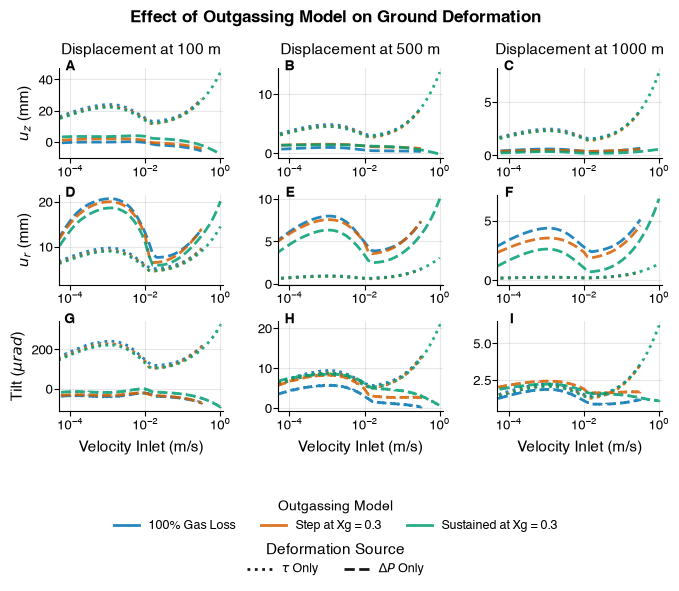

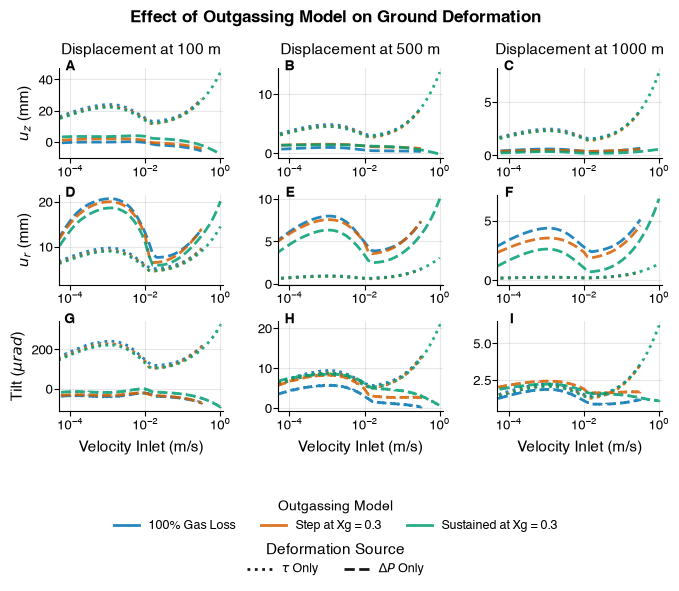

In [18]:
plot_conduit_analysis_fig2_with_ground_deformation_presentation(df, df_ge_test, colormap='batlow', figsize=(7, 5.5), save_plot=True)

In [46]:
def plot_combined_conduit_and_ground_deformation(
    df,
    df_ge,
    selected_velocities=(0.001, 0.1),
    figsize=(18, 13),
    save_plot=True,
    output_prefix='../../output_plots/3/figure2_combined_conduit_ground_deformation_june26'
):
    from matplotlib.ticker import MaxNLocator
    import matplotlib.pyplot as plt
    import matplotlib as mpl
    import numpy as np
    import pandas as pd
    import string

    mpl.rcParams.update({
        'font.family': 'sans-serif',
        'font.sans-serif': [
            'Helvetica', 'Arial', 'Liberation Sans', 'DejaVu Sans'
        ],
        'font.size': 11,
        'axes.labelsize': 11,
        'axes.titlesize': 11,
        'xtick.labelsize': 9.5,
        'ytick.labelsize': 9.5,
        'legend.fontsize': 10,
    })

    # ------------------------------------------------------------
    # Prepare data
    # ------------------------------------------------------------
    df_analysis = calculate_excess_pressure(df).copy()

    if 'Sb' in df_analysis.columns:
        df_analysis['1-Sb'] = 1 - df_analysis['Sb']

    color_list = ['#0072B2', '#D55E00', '#009E73']

    sb_labels = {
        0: '100% Gas Loss',
        4: 'Step at Xg = 0.3',
        6: 'Sustained at Xg = 0.3',
    }

    sb_options = [
        sb for sb in [0, 4, 6]
        if sb in df_analysis['Sb_option'].unique()
    ]

    sb_to_color = {
        sb: color_list[i]
        for i, sb in enumerate(sb_options)
    }

    sb_to_label = {
        sb: sb_labels.get(sb, f'Sb = {sb}')
        for sb in sb_options
    }

    # ------------------------------------------------------------
    # Maximum velocity from Sb = 0
    # ------------------------------------------------------------
    sb0_velocities = (
        df_analysis.loc[
            df_analysis['Sb_option'] == 0,
            'U_in'
        ]
        .dropna()
    )

    if sb0_velocities.empty:
        raise ValueError('No velocity data found for Sb_option == 0.')

    max_velocity_sb0 = sb0_velocities.max()

    # Only retain velocities within Sb = 0 range
    df_analysis = df_analysis[
        df_analysis['U_in'] <= max_velocity_sb0
    ].copy()

    df_ge_plot = df_ge[
        df_ge['U_in'] <= max_velocity_sb0
    ].copy()

    positive_velocities = pd.concat([
        df_analysis['U_in'],
        df_ge_plot['U_in']
    ]).dropna()

    positive_velocities = positive_velocities[
        positive_velocities > 0
    ]

    min_velocity = positive_velocities.min()

    # ------------------------------------------------------------
    # Plot definitions
    # ------------------------------------------------------------
    variables = {
        'Xg': r'$X_g$',
        'P_excess': r'$\Delta P$ (MPa)',
        'spf.mu*spf.sr': r'$\tau$ (MPa)',
    }

    distances = [100, 500, 1000]

    deformation_rows = [
        ('w2', r'$u_z$ (mm)'),
        ('u2', r'$u_r$ (mm)'),
        ('solid.RotrZ', r'Tilt ($\mu$rad)'),
    ]

    # ------------------------------------------------------------
    # GridSpec
    #
    # 6 columns total
    #
    # Row 0: inlet pressure spans all 6
    # Row 1: SIX depth-profile plots
    # Rows 2-4: ground deformation, 3 plots per row
    # ------------------------------------------------------------
    fig = plt.figure(figsize=figsize)

    gs = fig.add_gridspec(
    nrows=6,
    ncols=6,
    height_ratios=[
        0.9,   # inlet pressure
        0.2,  # spacer
        1.4,   # six conduit profiles
        1.0,   # vertical displacement
        1.0,   # radial displacement
        1.0,   # tilt
    ],
    hspace=0.3,
    wspace=0.35
    )
    # ============================================================
    # A. Inlet overpressure
    # ============================================================
    # inlet pressure
    ax_top = fig.add_subplot(gs[0, :])

  
    for sb in sb_options:

        df_sb = df_analysis[
            df_analysis['Sb_option'] == sb
        ]

        vel_plot = []
        p_plot = []

        for velocity in sorted(
            df_sb['U_in'].dropna().unique()
        ):

            df_vel = df_sb[
                df_sb['U_in'] == velocity
            ]

            if df_vel.empty:
                continue

            deepest_idx = df_vel['z'].idxmin()

            vel_plot.append(velocity)

            p_plot.append(
                df_vel.loc[
                    deepest_idx,
                    'P_excess'
                ] / 1e6
            )

        ax_top.semilogx(
            vel_plot,
            p_plot,
            color=sb_to_color[sb],
            linewidth=2.5,
            label=sb_to_label[sb]
        )

    for velocity in selected_velocities:
        ax_top.axvline(
            velocity,
            color='0.45',
            linestyle='--',
            linewidth=1,
            alpha=0.7
        )

    ax_top.set_xlim(
        min_velocity * 0.8,
        max_velocity_sb0 * 1.05
    )

    ax_top.set_xlabel('Inlet Velocity (m/s)')
    ax_top.set_ylabel(r'Inlet $\Delta P$ (MPa)')

    ax_top.grid(True, alpha=0.3)

    ax_top.spines['top'].set_visible(False)
    ax_top.spines['right'].set_visible(False)

    ax_top.legend(
        loc='upper left',
        fontsize=8,
        frameon=True,
        framealpha=0.9,
        borderpad=0.25,
        labelspacing=0.25,
        handlelength=1.5,
        handletextpad=0.4,
        borderaxespad=0.3,
        title='Outgassing Model',
        title_fontsize=8
    )
    # ============================================================
    # B-G. SIX depth-profile plots in ONE ROW
    #
    # Layout:
    #
    # velocity 1:
    # Xg | dP | tau
    #
    # velocity 2:
    # Xg | dP | tau
    #
    # All six occupy one GridSpec column each
    # ============================================================
    conduit_axes = []

    profile_number = 0

    for velocity in selected_velocities:

        for var, var_name in variables.items():

            # conduit profiles
            ax = fig.add_subplot(gs[2, profile_number])
        
                
            conduit_axes.append(ax)

            for sb in sb_options:

                data = df_analysis[
                    (
                        df_analysis['Sb_option'] == sb
                    )
                    &
                    np.isclose(
                        df_analysis['U_in'],
                        velocity
                    )
                ].sort_values('z')

                if data.empty or var not in data.columns:
                    continue

                if var in ['spf.mu*spf.sr', 'P_excess']:
                    x = data[var] / 1e6
                else:
                    x = data[var]

                ax.plot(
                    x,
                    data['z'] / 1e3,
                    color=sb_to_color[sb],
                    linewidth=2
                )

            # Formatting
            if var == 'Xg':
                ax.set_xticks([0, 0.3])

            elif var == 'spf.mu*spf.sr':
                # make x-axis log scale for tau
                ax.set_xscale('log')
                pass 
                # if np.isclose(velocity, 0.1):
                #     ax.set_xticks([0, 0.15])
                # else:
                #     ax.set_xticks([0, 2])

            else:
                ax.xaxis.set_major_locator(
                    MaxNLocator(nbins=3)
                )

            ax.xaxis.set_ticks_position('top')
            ax.xaxis.set_label_position('top')

            ax.set_xlabel(var_name, labelpad=4)

            # Only first plot of each velocity block gets depth label
            if var == 'Xg':
                ax.set_ylabel('Depth (km)')
            else:
                ax.tick_params(labelleft=False)

            ax.grid(True, alpha=0.3)

            ax.spines['bottom'].set_visible(False)
            ax.spines['right'].set_visible(False)

            # velocity annotation in bottom-right of each profile plot
            ax.text(
                0.95,
                0.05,
                f'{velocity:g} m/s',
                transform=ax.transAxes,
                ha='right',
                va='bottom',
                bbox=dict(
                    boxstyle='round,pad=0.25',
                    facecolor='0.95',
                    edgecolor='0.7',
                    linewidth=0.8,
                    alpha=0.9
                )
            )

            profile_number += 1

    # ============================================================
    # Ground deformation
    #
    # 3 plots per row, each spanning TWO GridSpec columns
    # ============================================================
    deformation_axes = []
    # deformation rows
            
    for row_offset, (disp_var, disp_name) in enumerate(
        deformation_rows
    ):

        gs_row = row_offset + 3 # deformation rows start at row 3

        for col_idx, r_from_cond in enumerate(
            distances
        ):

            col_start = col_idx * 2

            ax = fig.add_subplot(
                gs[
                    gs_row,
                    col_start:col_start + 2
                ]
            )

            deformation_axes.append(ax)

            for param_def in [0, 2]:

                for sb in sb_options:

                    mask = (
                        (
                            df_ge_plot['Sb_option'] == sb
                        )
                        &
                        (
                            df_ge_plot['r'] == r_from_cond
                        )
                    )

                    if 'param_def' in df_ge_plot.columns:
                        mask &= (
                            df_ge_plot['param_def'] == param_def
                        )

                    data = (
                        df_ge_plot.loc[mask]
                        .sort_values('U_in')
                    )

                    if (
                        data.empty
                        or disp_var not in data.columns
                    ):
                        continue

                    x = data['U_in'].to_numpy()

                    if disp_var == 'solid.RotrZ':
                        y = (
                            data[disp_var].to_numpy()
                            * 1e6
                        )
                    else:
                        y = (
                            data[disp_var].to_numpy()
                            * 1e3
                        )

                    linestyle = (
                        ':'
                        if param_def == 0
                        else '--'
                    )

                    ax.semilogx(
                        x,
                        y,
                        color=sb_to_color[sb],
                        linewidth=2,
                        linestyle=linestyle
                    )

            ax.set_xlim(
                min_velocity * 0.8,
                max_velocity_sb0 * 1.05
            )

            ax.grid(True, alpha=0.3)

            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)

            ax.xaxis.set_ticks_position('bottom')
            ax.xaxis.set_label_position('bottom')

            ax.tick_params(
                axis='x',
                which='both',
                top=False,
                labeltop=False,
                bottom=True,
                labelbottom=True
            )
            if row_offset == 0:
                ax.set_title(
                    f'{r_from_cond} m'
                )

            if col_idx == 0:
                ax.set_ylabel(
                    disp_name
                )
            else:
                pass
                # ax.tick_params(
                #     labelleft=False
                # )

            if row_offset == 2:
                ax.set_xlabel(
                    'Velocity Inlet (m/s)'
                )

    # ------------------------------------------------------------
    # Panel letters
    # ------------------------------------------------------------
    all_axes = (
        [ax_top]
        + conduit_axes
        + deformation_axes
    )

    for label, ax in zip(
        string.ascii_uppercase,
        all_axes
    ):
        ax.text(
            0.02,
            0.96,
            label,
            transform=ax.transAxes,
            fontsize=10,
            fontweight='bold',
            va='top',
            ha='left'
        )

    # ------------------------------------------------------------
    # Legends
    # ------------------------------------------------------------
    color_handles = [
        plt.Line2D(
            [0], [0],
            color=sb_to_color[sb],
            lw=2.5
        )
        for sb in sb_options
    ]

    color_labels = [
        sb_to_label[sb]
        for sb in sb_options
    ]

    style_handles = [
        plt.Line2D(
            [0], [0],
            color='k',
            lw=2,
            linestyle=':'
        ),
        plt.Line2D(
            [0], [0],
            color='k',
            lw=2,
            linestyle='--'
        ),
    ]

    fig.legend(
        color_handles,
        color_labels,
        ncol=3,
        loc='lower center',
        bbox_to_anchor=(0.5, 0.025),
        frameon=False,
        title='Outgassing Model'
    )

    fig.legend(
        style_handles,
        [
            r'$\tau$ Only',
            r'$\Delta P$ Only'
        ],
        ncol=2,
        loc='lower center',
        bbox_to_anchor=(0.5, -0.005),
        frameon=False,
        title='Deformation Source'
    )

    fig.subplots_adjust(
        left=0.065,
        right=0.985,
        top=0.97,
        bottom=0.11
    )

    # ------------------------------------------------------------
    # Save
    # ------------------------------------------------------------
    if save_plot:

        fig.savefig(
            output_prefix + '.png',
            dpi=300,
            bbox_inches='tight'
        )

        fig.savefig(
            output_prefix + '.pdf',
            dpi=300,
            bbox_inches='tight'
        )

        fig.savefig(
            output_prefix + '.svg',
            dpi=300,
            bbox_inches='tight'
        )

    return fig, max_velocity_sb0

Debug: z range: -3000.0 to 0.0
Debug: depth range: -0.0 to 3000.0
Debug: linproj_r range: 2209327.5037057796 to 114920000.0
Debug: P_excess range: -8008361.100000009 to 32859594.799999997
Max Sb=0 velocity used for all curves: 0.31623 m/s


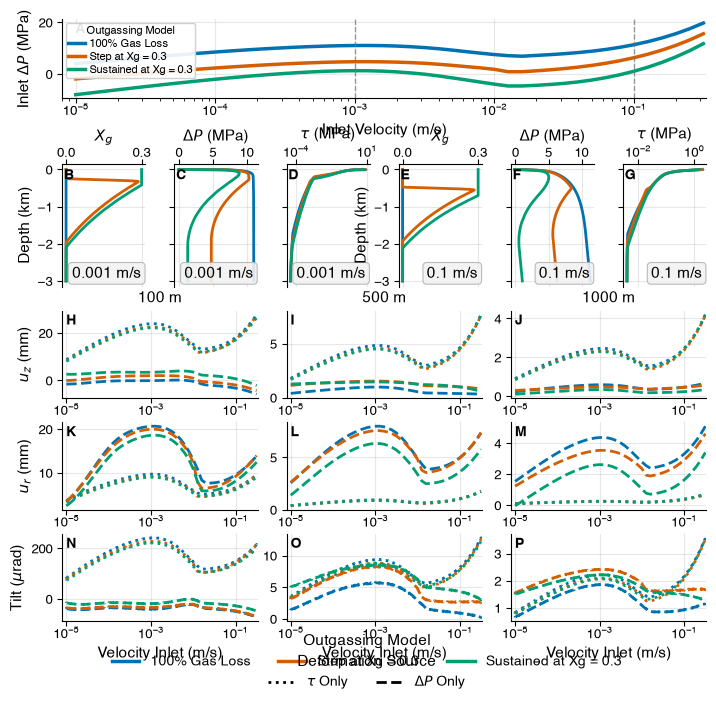

In [47]:
combined_fig, max_velocity_sb0 = plot_combined_conduit_and_ground_deformation(
    df,
    df_ge_test,
    selected_velocities=(0.001, 0.1),
    figsize=(7, 7),
    save_plot=True
)
print(f'Max Sb=0 velocity used for all curves: {max_velocity_sb0:g} m/s')

In [ ]:
def plot_combined_conduit_and_ground_deformation(
    df,
    df_ge,
    selected_velocities=(0.001, 0.1),
    figsize=(18, 13),
    save_plot=True,
    output_prefix='../../output_plots/3/figure2_combined_conduit_ground_deformation_june26'
):
    from matplotlib.ticker import MaxNLocator
    import matplotlib.pyplot as plt
    import matplotlib as mpl
    import numpy as np
    import pandas as pd
    import string
    from matplotlib.ticker import MaxNLocator, MultipleLocator

    mpl.rcParams.update({
        'font.family': 'sans-serif',
        'font.sans-serif': [
            'Helvetica', 'Arial', 'Liberation Sans', 'DejaVu Sans'
        ],
        'font.size': 11,
        'axes.labelsize': 11,
        'axes.titlesize': 11,
        'xtick.labelsize': 9.5,
        'ytick.labelsize': 9.5,
        'legend.fontsize': 10,
    })

    # ------------------------------------------------------------
    # Prepare data
    # ------------------------------------------------------------
    df_analysis = calculate_excess_pressure(df).copy()

    if 'Sb' in df_analysis.columns:
        df_analysis['1-Sb'] = 1 - df_analysis['Sb']

    color_list = ['#0072B2', '#D55E00', '#009E73']

    sb_labels = {
        0: '100% Gas Loss',
        4: 'Step at Xg = 0.3',
        6: 'Sustained at Xg = 0.3',
    }

    sb_options = [
        sb for sb in [0, 4, 6]
        if sb in df_analysis['Sb_option'].unique()
    ]

    sb_to_color = {
        sb: color_list[i]
        for i, sb in enumerate(sb_options)
    }

    sb_to_label = {
        sb: sb_labels.get(sb, f'Sb = {sb}')
        for sb in sb_options
    }

    # ------------------------------------------------------------
    # Maximum velocity from Sb = 0
    # ------------------------------------------------------------
    sb0_velocities = (
        df_analysis.loc[
            df_analysis['Sb_option'] == 0,
            'U_in'
        ]
        .dropna()
    )

    if sb0_velocities.empty:
        raise ValueError('No velocity data found for Sb_option == 0.')

    max_velocity_sb0 = sb0_velocities.max()

    # Only retain velocities within the Sb = 0 velocity range
    df_analysis = df_analysis[
        df_analysis['U_in'] <= max_velocity_sb0
    ].copy()

    df_ge_plot = df_ge[
        df_ge['U_in'] <= max_velocity_sb0
    ].copy()

    positive_velocities = pd.concat([
        df_analysis['U_in'],
        df_ge_plot['U_in']
    ]).dropna()

    positive_velocities = positive_velocities[
        positive_velocities > 0
    ]

    min_velocity = positive_velocities.min()

    # ------------------------------------------------------------
    # Plot definitions
    # ------------------------------------------------------------
    variables = {
        'Xg': r'$X_g$',
        'P_excess': r'$\Delta P$ (MPa)',
        'spf.mu*spf.sr': r'$\tau$ (MPa)',
    }

    # Ground deformation rows are now distance
    distances = [250, 1000]

    # Ground deformation columns
    deformation_cols = [
        ('w2', r'$u_z$ (mm)'),
        ('u2', r'$u_r$ (mm)'),
        ('solid.RotrZ', r'Tilt ($\mu$rad)'),
    ]

    # ------------------------------------------------------------
    # GridSpec
    #
    # 6 columns total
    #
    # Row 0: inlet pressure
    # Row 1: spacer
    # Row 2: six conduit profiles
    # Row 3: deformation at 250 m
    # Row 4: deformation at 1000 m
    # ------------------------------------------------------------
    fig = plt.figure(figsize=figsize)

    gs = fig.add_gridspec(
        nrows=5,
        ncols=6,
        height_ratios=[
            0.9,   # inlet pressure
            0.2,   # spacer
            1.4,   # six conduit profiles
            1.0,   # deformation at 250 m
            1.0,   # deformation at 1000 m
        ],
        hspace=0.3,
        wspace=0.35
    )

    # ============================================================
    # A. Inlet overpressure
    # ============================================================
    ax_top = fig.add_subplot(gs[0, :])

    for sb in sb_options:

        df_sb = df_analysis[
            df_analysis['Sb_option'] == sb
        ]

        vel_plot = []
        p_plot = []

        for velocity in sorted(
            df_sb['U_in'].dropna().unique()
        ):

            df_vel = df_sb[
                df_sb['U_in'] == velocity
            ]

            if df_vel.empty:
                continue

            deepest_idx = df_vel['z'].idxmin()

            vel_plot.append(velocity)

            p_plot.append(
                df_vel.loc[
                    deepest_idx,
                    'P_excess'
                ] / 1e6
            )

        ax_top.semilogx(
            vel_plot,
            p_plot,
            color=sb_to_color[sb],
            linewidth=1,
            label=sb_to_label[sb]
        )

    # Mark selected conduit-profile velocities
    for velocity in selected_velocities:
        ax_top.axvline(
            velocity,
            color='0.45',
            linestyle='--',
            linewidth=1,
            alpha=0.7
        )

    ax_top.set_xlim(
        min_velocity * 0.8,
        max_velocity_sb0 * 1.05
    )

    ax_top.set_xlabel('Inlet Velocity (m/s)')
    ax_top.set_ylabel(r'Inlet $\Delta P$ (MPa)')

    ax_top.grid(True, alpha=0.3)

    ax_top.spines['top'].set_visible(False)
    ax_top.spines['right'].set_visible(False)

    # Compact outgassing-model legend
    ax_top.legend(
        loc='upper left',
        fontsize=9,
        frameon=True,
        framealpha=0.9,
        borderpad=0.4,
        labelspacing=0.15,
        handlelength=1.2,
        handletextpad=0.3,
        borderaxespad=0.2,
        title='Outgassing Model',
        title_fontsize=9
    )

    # ============================================================
    # B-G. SIX depth-profile plots in ONE ROW
    #
    # 0.001 m/s:
    # Xg | dP | tau
    #
    # 0.1 m/s:
    # Xg | dP | tau
    # ============================================================
    conduit_axes = []

    profile_number = 0

    for velocity in selected_velocities:

        for var, var_name in variables.items():

            ax = fig.add_subplot(
                gs[2, profile_number]
            )

            conduit_axes.append(ax)

            for sb in sb_options:

                data = df_analysis[
                    (
                        df_analysis['Sb_option'] == sb
                    )
                    &
                    np.isclose(
                        df_analysis['U_in'],
                        velocity
                    )
                ].sort_values('z')

                if data.empty or var not in data.columns:
                    continue

                if var in ['spf.mu*spf.sr', 'P_excess']:
                    x = data[var] / 1e6
                else:
                    x = data[var]

                ax.plot(
                    x,
                    data['z'] / 1e3,
                    color=sb_to_color[sb],
                    linewidth=1
                )

            # ----------------------------------------------------
            # Conduit x-axis formatting
            # ----------------------------------------------------
            if var == 'Xg':
                # Major ticks
                ax.set_xticks([0, 0.3])

                # Minor ticks every 0.1 Xg
                ax.xaxis.set_minor_locator(
                    MultipleLocator(0.1)
                )

                # Minor vertical grid lines
                ax.grid(
                    True,
                    which='minor',
                    axis='x',
                    alpha=0.15,
                    linestyle=':'
                )
            elif var == 'spf.mu*spf.sr':

                # Log scale for shear stress
                ax.set_xscale('log')

            else:

                ax.xaxis.set_major_locator(
                    MaxNLocator(nbins=3)
                )

            # x-axis at top for conduit profiles
            ax.xaxis.set_ticks_position('top')
            ax.xaxis.set_label_position('top')

            ax.set_xlabel(
                var_name,
                labelpad=4
            )

            # Keep depth labels for both Xg plots
            if var == 'Xg':
                ax.set_ylabel('z (km)')
            else:
                ax.tick_params(
                    axis='y',
                    labelleft=True
                )

            ax.grid(True, alpha=0.3)

            ax.spines['bottom'].set_visible(False)
            ax.spines['right'].set_visible(False)

            # ----------------------------------------------------
            # Velocity annotation in bottom-right
            # ----------------------------------------------------
            ax.text(
                0.95,
                0.05,
                f'{velocity:g} m/s',
                transform=ax.transAxes,
                ha='right',
                va='bottom',
                fontsize=8,
                bbox=dict(
                    boxstyle='round,pad=0.25',
                    facecolor='0.95',
                    edgecolor='0.7',
                    linewidth=0.8,
                    alpha=0.9
                )
            )
            ax.yaxis.set_minor_locator(MultipleLocator(0.25))

            # Grid
            ax.grid(
                True,
                which='major',
                alpha=0.3
            )

            ax.grid(
                True,
                which='minor',
                axis='y',
                alpha=0.15,
                linestyle=':'
            )
            # Major/minor depth ticks

            profile_number += 1
    # set every column besides first to have no y tick labels 
    for ax in conduit_axes[1:]:
        ax.tick_params(
            axis='y',
            labelleft=False
        )

    # ============================================================
    # Ground deformation
    #
    # ROWS = distance from conduit:
    #   Row 3 = 250 m
    #   Row 4 = 1000 m
    #
    # COLUMNS:
    #   vertical displacement | radial displacement | tilt
    # ============================================================
    deformation_axes = []

    for row_offset, r_from_cond in enumerate(distances):

        gs_row = row_offset + 3

        for col_idx, (disp_var, disp_name) in enumerate(
            deformation_cols
        ):

            # Each deformation plot spans two GridSpec columns
            col_start = col_idx * 2

            ax = fig.add_subplot(
                gs[
                    gs_row,
                    col_start:col_start + 2
                ]
            )

            deformation_axes.append(ax)

            for param_def in [0, 2]:

                for sb in sb_options:

                    mask = (
                        (
                            df_ge_plot['Sb_option'] == sb
                        )
                        &
                        (
                            df_ge_plot['r'] == r_from_cond
                        )
                    )

                    if 'param_def' in df_ge_plot.columns:
                        mask &= (
                            df_ge_plot['param_def']
                            == param_def
                        )

                    data = (
                        df_ge_plot.loc[mask]
                        .sort_values('U_in')
                    )

                    if (
                        data.empty
                        or disp_var not in data.columns
                    ):
                        continue

                    x = data['U_in'].to_numpy()

                    if disp_var == 'solid.RotrZ':

                        # rad -> microradians
                        y = (
                            data[disp_var].to_numpy()
                            * 1e6
                        )

                    else:

                        # m -> mm
                        y = (
                            data[disp_var].to_numpy()
                            * 1e3
                        )

                    linestyle = (
                        ':'
                        if param_def == 0
                        else '--'
                    )

                    ax.semilogx(
                        x,
                        y,
                        color=sb_to_color[sb],
                        linewidth=1,
                        linestyle=linestyle
                    )

            # ----------------------------------------------------
            # Deformation formatting
            # ----------------------------------------------------
            ax.set_xlim(
                min_velocity * 0.8,
                max_velocity_sb0 * 1.05
            )

            ax.grid(True, alpha=0.3)

            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)

            # Explicitly keep x ticks on bottom only
            ax.xaxis.set_ticks_position('bottom')
            ax.xaxis.set_label_position('bottom')

            ax.tick_params(
                axis='x',
                which='both',
                top=False,
                labeltop=False,
                bottom=True,
                labelbottom=True
            )

            # Keep y tick labels on EVERY deformation panel
            ax.tick_params(
                axis='y',
                which='both',
                left=True,
                labelleft=True
            )

            # ----------------------------------------------------
            # Column headings = deformation quantity
            # ----------------------------------------------------
            # if row_offset == 0:
            #     ax.set_title(
            #         disp_name,
            #         pad=6
            #     )
            
            ax.set_ylabel(
                    disp_name,labelpad=0)
            # move yticklabels closer to y-axis
            ax.tick_params(
                axis='y',
                which='major',
                pad=0.05
            )
            # ----------------------------------------------------
            # Distance label in first panel of each row
            # ----------------------------------------------------
            # if col_idx == 0:

            ax.text(
                0.02,
                0.85,
                f'$r$ = {r_from_cond} m',
                transform=ax.transAxes,
                ha='left',
                va='top',
                fontsize=9,
                bbox=dict(
                    boxstyle='round,pad=0.2',
                    facecolor='0.95',
                    edgecolor='0.7',
                    linewidth=0.7,
                    alpha=0.9
                )
            )
            if row_offset == 0 and col_idx == 1:
                ax.set_title(
                    r'Deformation at $r = 250$ and $1000$ m ' +
                 
                    r'($\tau$-induced $\cdots\cdots$  and  $\Delta P$-induced $--$)',
                    pad=8,
                    fontsize=9
                )

            # Only bottom deformation row gets x-axis title
            if row_offset == len(distances) - 1:

                ax.set_xlabel(
                    'Inlet Velocity (m/s)'
                )

    # ------------------------------------------------------------
    # Panel letters
    # ------------------------------------------------------------
    all_axes = (
        [ax_top]
        + conduit_axes
        + deformation_axes
    )

    for label, ax in zip(
        string.ascii_uppercase,
        all_axes
    ):

        ax.text(
            0.02,
            0.96,
            label,
            transform=ax.transAxes,
            fontsize=10,
            fontweight='bold',
            va='top',
            ha='left',
            zorder=100
        )

    # ------------------------------------------------------------
    # Deformation-source legend
    # ------------------------------------------------------------
    style_handles = [
        plt.Line2D(
            [0], [0],
            color='k',
            lw=2,
            linestyle=':'
        ),
        plt.Line2D(
            [0], [0],
            color='k',
            lw=2,
            linestyle='--'
        ),
    ]

    # fig.legend(
    #     style_handles,
    #     [
    #         r'$\tau$ Only',
    #         r'$\Delta P$ Only'
    #     ],
    #     ncol=2,
    #     loc='lower center',
    #     bbox_to_anchor=(0.5, 0.025),
    #     frameon=False,
    #     title='Deformation Source'
    # )

    # ------------------------------------------------------------
    # Figure spacing
    # ------------------------------------------------------------
    fig.subplots_adjust(
        left=0.065,
        right=0.985,
        top=0.97,
        bottom=0.10
    )

    # ------------------------------------------------------------
    # Save
    # ------------------------------------------------------------
    if save_plot:

        fig.savefig(
            output_prefix + '.png',
            dpi=300,
            bbox_inches='tight'
        )

        fig.savefig(
            output_prefix + '.pdf',
            dpi=300,
            bbox_inches='tight'
        )

        fig.savefig(
            output_prefix + '.svg',
            dpi=300,
            bbox_inches='tight'
        )

    return fig, max_velocity_sb0


combined_fig, max_velocity_sb0 = plot_combined_conduit_and_ground_deformation(
    df,
    df_ge_test,
    selected_velocities=(0.001, 0.1),
    figsize=(7, 7),
    save_plot=True
)
print(f'Max Sb=0 velocity used for all curves: {max_velocity_sb0:g} m/s')

Debug: z range: -3000.0 to 0.0
Debug: depth range: -0.0 to 3000.0
Debug: linproj_r range: 2209327.5037057796 to 114920000.0
Debug: P_excess range: -8008361.100000009 to 32859594.799999997
